# Time to next purchase and censoring

Source: Chen (2012), Online Retail II, UCI, CC BY 4.0. Run the pipeline before this notebook. Figures describe historical purchases, not loyalty membership or causal offer effects.

In [1]:
from pathlib import Path
import json, pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/'configs').exists() else Path.cwd().parent
plt.style.use('seaborn-v0_8-whitegrid')


In [2]:
from loyalty_ml.train_survival import train, survival_features
from lifelines.statistics import proportional_hazard_test
x=pd.read_parquet(ROOT/'data/processed/customer_snapshots.parquet')
landmark=x[x.snapshot_date=='2011-03-01']
cox,km=train(landmark)
cox.summary[['coef','exp(coef)','p']]

,coef,exp(coef),p
covariate,,,
recency_days,-0.078866,0.924163,1.338738e-03
frequency_180,0.448841,1.566496,7.745133e-21
spend_180,0.166292,1.180918,5.751512e-40
average_order_value,0.013774,1.013870,5.881559e-01
products_180,0.088353,1.092373,5.158555e-04
spend_30,0.020149,1.020353,3.553109e-02
spend_90,0.020578,1.020791,9.027911e-03
frequency_90,0.249008,1.282752,3.257786e-05
observed_tenure_days,0.188573,1.207525,1.579454e-09


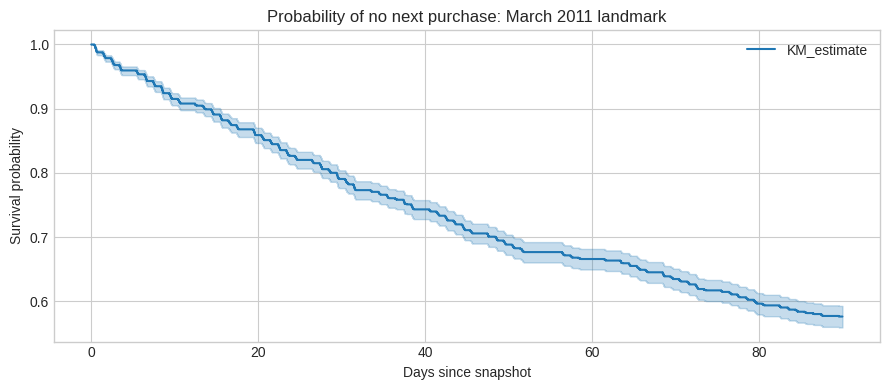

In [3]:
km.plot_survival_function(figsize=(9,4))
plt.title('Probability of no next purchase: March 2011 landmark')
plt.xlabel('Days since snapshot');plt.ylabel('Survival probability');plt.tight_layout();plt.show()

In [4]:
diagnostic=proportional_hazard_test(cox,survival_features(landmark),time_transform='rank')
diagnostic.summary.sort_values('p')

,test_statistic,p,-log2(p)
recency_days,9.730248,0.001813,9.107723
spend_180,7.095319,0.007729,7.015586
observed_tenure_days,3.953552,0.046773,4.418195
frequency_180,3.314973,0.068651,3.864566
frequency_90,2.169379,0.140783,2.828454
spend_90,1.832068,0.175883,2.507308
spend_30,1.771162,0.183238,2.448207
products_180,0.658920,0.416942,1.262083
average_order_value,0.092828,0.760612,0.394767


## Interpretation
Compare against the baseline and report limitations. No purchase for 90 days does not prove permanent churn. Large wholesale purchases can dominate spending error. Survival diagnostics can reject proportional hazards; the Cox model is exploratory if that assumption fails. Retention priority is a heuristic requiring an experiment before claiming campaign benefit.